# moss: the loss behind the moss

The moss on my homepage isn't random noise. It grows the way real moss spreads, using two distributions from ecology:

1. **Where spores land:** a fat-tailed dispersal kernel
2. **When ferns rise:** Weibull waiting times

This notebook explains both, checks that they're sampled correctly, and shows why the shape of a distribution's tail matters more than its average.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(0)

## 1. What a dispersal kernel is

A **dispersal kernel** is the probability distribution of how far an offspring (a seed or spore) lands from its parent.

Two kernels can have the same *average* distance and still behave very differently, because what matters for spreading is the **tail**: how often a rare offspring travels much farther than usual. A thin tail (Gaussian, exponential) makes long jumps vanishingly rare. A fat tail (lognormal here) makes them uncommon but real, and those few long jumps end up driving how fast a population spreads.

## 2. Three kernels, side by side

Distances are drawn from a 2-D Gaussian, an exponential and a lognormal, each scaled to **the same mean distance (1)**, so only their shapes differ. Each kernel is a distribution of distance; a landing spot pairs that distance with a uniform random direction.

In [2]:
n = 100_000
mean_dist = 1.0  # every kernel is scaled so its mean distance is this

# Gaussian: 2D normal displacement, so the distance is Rayleigh with mean sigma * sqrt(pi/2)
sigma_g = mean_dist / np.sqrt(np.pi / 2)
d_gauss = np.hypot(rng.normal(0, sigma_g, n), rng.normal(0, sigma_g, n))

# Exponential: mean distance equals the scale
d_exp = rng.exponential(mean_dist, n)

# Lognormal: mean is exp(mu + s^2 / 2), so pick a shape s and solve for mu
s_ln = 1.5  # tail heaviness: at 1.0 the spread is faster but steady; at 1.5 it accelerates (section 3)
mu_ln = np.log(mean_dist) - s_ln**2 / 2
d_lognorm = rng.lognormal(mu_ln, s_ln, n)

kernels = {'gaussian': d_gauss, 'exponential': d_exp, 'lognormal': d_lognorm}
for name, d in kernels.items():
    print(f'{name:12s} mean={d.mean():.3f}  median={np.median(d):.3f}  99.9th pct={np.quantile(d, 0.999):.2f}')

gaussian     mean=1.001  median=0.940  99.9th pct=2.98
exponential  mean=1.004  median=0.693  99.9th pct=7.15
lognormal    mean=0.999  median=0.325  99.9th pct=35.01


In [3]:
# Plot style, shared by every figure in this notebook.
# One accent: the fat-tailed kernel is moss green.
# The two thin-tailed kernels are grays, told apart by lightness and direct labels.
# Lightness order (light gray, green, near-black) keeps all three apart under colour blindness.
from pathlib import Path
from matplotlib.ticker import FixedLocator, FixedFormatter

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

SURFACE, INK, INK_2, INK_3, HAIRLINE = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8983", "#e4e3de"
COLORS = {"gaussian": "#b3b1aa", "exponential": "#3a3936", "lognormal": "#3c8a43"}  # CVD-checked: every pair ΔE ≥ 18
LABELS = {"gaussian": "Gaussian (2-D)", "exponential": "Exponential", "lognormal": "Lognormal"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 11, "text.color": INK,
    "axes.edgecolor": HAIRLINE, "axes.linewidth": 0.8, "axes.labelcolor": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.titlepad": 10,
    "xtick.color": INK_3, "ytick.color": INK_3, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "xtick.major.size": 0, "ytick.major.size": 0, "xtick.minor.size": 0, "ytick.minor.size": 0,
    "legend.frameon": False,
    "lines.solid_capstyle": "round",
    "mathtext.fontset": "custom",   # formulas in the same typeface as the text
    "mathtext.rm": "Helvetica Neue", "mathtext.it": "Helvetica Neue:italic", "mathtext.bf": "Helvetica Neue:bold",
    "mathtext.sf": "Helvetica Neue", "mathtext.cal": "Helvetica Neue",
})

In [4]:
# The formulas behind the samples above, with the same parameters.
dists = {
    "gaussian": stats.rayleigh(scale=sigma_g),                    # distance of a 2-D Gaussian
    "exponential": stats.expon(scale=mean_dist),
    "lognormal": stats.lognorm(s=s_ln, scale=np.exp(mu_ln)),
}

for name, k in dists.items():
    d = kernels[name]
    ks = stats.kstest(d, k.cdf)
    print(f"{LABELS[name]:12s} mean {k.mean():.3f} (formula) vs {d.mean():.3f} (sample)   KS p = {ks.pvalue:.2f}   "
          f"beyond 10×: {(d > 10).sum():4d} seen vs {n * k.sf(10):8.2f} expected")
    assert ks.pvalue > 0.01, f"{name}: samples don't match the formula"

Gaussian (2-D) mean 1.000 (formula) vs 1.001 (sample)   KS p = 0.88   beyond 10×:    0 seen vs     0.00 expected
Exponential  mean 1.000 (formula) vs 1.004 (sample)   KS p = 0.89   beyond 10×:    8 seen vs     4.54 expected
Lognormal    mean 1.000 (formula) vs 0.999 (sample)   KS p = 0.34   beyond 10×: 1086 seen vs  1115.48 expected


### Figure 1: where 10,000 spores land

Same parent, same average distance, three kernels. The panels share one scale, so the differences are real.

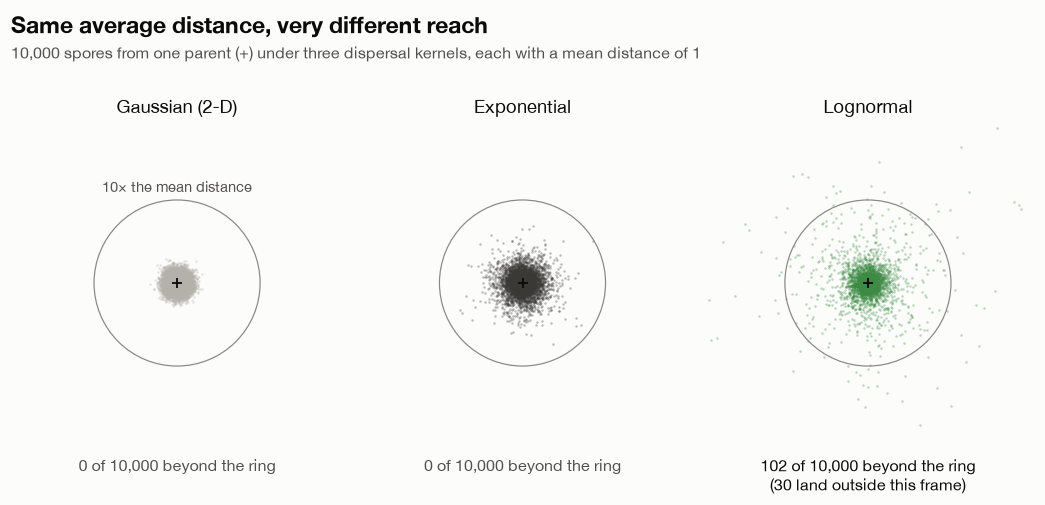

In [5]:
R_RING = 10   # reference ring, in mean distances
LIM = 20      # half-width of each panel, same for all three

fig, axes = plt.subplots(1, 3, figsize=(12, 4.9), sharex=True, sharey=True)
fig.subplots_adjust(wspace=0.04, top=0.80, bottom=0.12)

N = 10_000   # first 10,000 of the n samples; they're i.i.d., so any 10,000 will do
for ax, name in zip(axes, kernels):
    d = kernels[name][:N]
    th = rng.uniform(0, 2 * np.pi, size=N)
    x, y = d * np.cos(th), d * np.sin(th)
    ax.scatter(x, y, s=2.5, color=COLORS[name], alpha=0.35, linewidths=0, rasterized=True)
    ax.add_patch(plt.Circle((0, 0), R_RING, fill=False, color=INK_3, lw=0.8))
    ax.plot(0, 0, marker="+", color=INK, ms=7, mew=1.2)

    beyond = int((d > R_RING).sum())
    off_frame = int(((np.abs(x) > LIM) | (np.abs(y) > LIM)).sum())
    note = f"{beyond} of {N:,} beyond the ring"
    if off_frame:
        note += f"\n({off_frame} land outside this frame)"
    ax.text(0.5, -0.02, note, transform=ax.transAxes, ha="center", va="top", fontsize=10.5,
            color=INK if beyond else INK_2)

    ax.set_title(LABELS[name], color=INK, loc="center", pad=2)
    ax.set_xlim(-LIM, LIM)
    ax.set_ylim(-LIM, LIM)
    ax.set_aspect("equal")
    ax.set_axis_off()

axes[0].text(0, R_RING + 0.6, "10× the mean distance", ha="center", va="bottom", fontsize=9.5, color=INK_2)

fig.text(0.125, 0.965, "Same average distance, very different reach", fontsize=15, weight="bold", va="top")
fig.text(0.125, 0.905, f"{N:,} spores from one parent (+) under three dispersal kernels, each with a mean distance of 1",
         fontsize=10.5, color=INK_2, va="top")

fig.savefig(FIGURES / "fig1_landing_spots.png")
plt.show()

### Figure 2: the shape of each kernel

Left: the density near the parent. Right: the survival function P(distance > r) on a log scale, which is where tails become visible. Both are drawn from the formulas, not from samples.

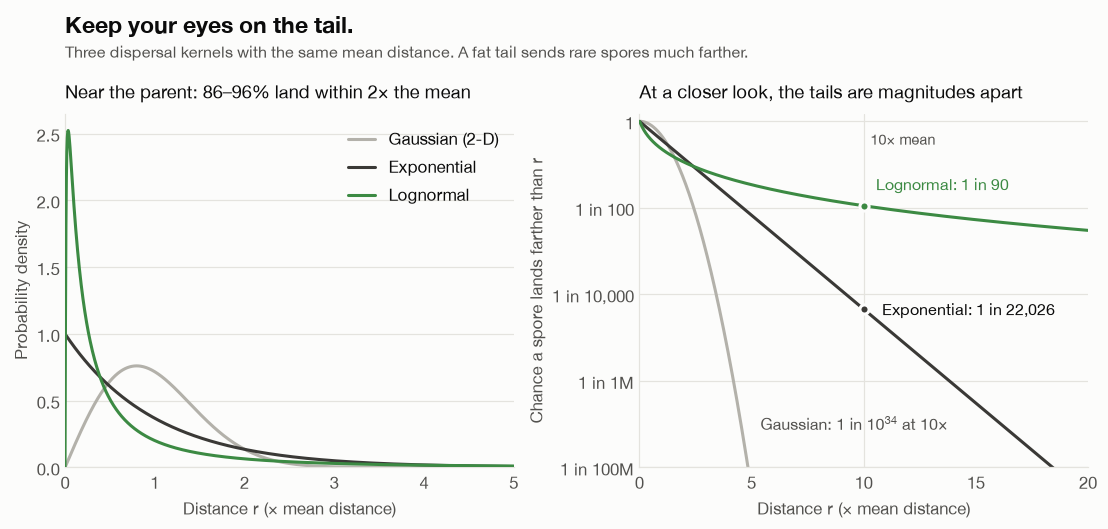

In [6]:
r = np.linspace(0, 20, 4001)
FLOOR = 1e-8   # lowest probability shown on the right

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"wspace": 0.28})
fig.subplots_adjust(top=0.78)

# Left: density, near the parent
near = r[r <= 5]
for name, k in dists.items():
    left.plot(near, k.pdf(near), color=COLORS[name], lw=2, label=LABELS[name],
              zorder=3 if name == "lognormal" else 2)
left.set_xlim(0, 5)
left.set_ylim(0, 1.05 * max(k.pdf(near).max() for k in dists.values()))
left.grid(axis="y", color=HAIRLINE, lw=0.8)
left.set_xlabel("Distance r (× mean distance)")
left.set_ylabel("Probability density")
within_2 = [100 * k.cdf(2) for k in dists.values()]
left.set_title(f"Near the parent: {min(within_2):.0f}–{max(within_2):.0f}% land within 2× the mean", color=INK)
left.legend(loc="upper right", handlelength=1.6)

# Right: survival function, log scale
for name, k in dists.items():
    sf = k.sf(r)
    keep = sf >= FLOOR * 0.5
    right.plot(r[keep], sf[keep], color=COLORS[name], lw=2, zorder=3 if name == "lognormal" else 2)
right.set_yscale("log")
right.set_xlim(0, 20)
right.set_xticks([0, 5, 10, 15, 20])
right.set_ylim(FLOOR, 1.5)
ticks = [1, 1e-2, 1e-4, 1e-6, 1e-8]
right.yaxis.set_major_locator(FixedLocator(ticks))
right.yaxis.set_major_formatter(FixedFormatter(["1", "1 in 100", "1 in 10,000", "1 in 1M", "1 in 100M"]))
right.yaxis.set_minor_locator(FixedLocator([]))
right.grid(axis="y", color=HAIRLINE, lw=0.8)
right.axvline(R_RING, color=HAIRLINE, lw=0.8, zorder=1)
right.set_xlabel("Distance r (× mean distance)")
right.set_ylabel("Chance a spore lands farther than r")
right.set_title("At a closer look, the tails are magnitudes apart", color=INK)

# Direct labels: where each spore type stands at 10× the mean distance
def one_in(p):
    return f"1 in {1 / p:,.0f}"

LABEL_OFFSET = {"lognormal": (8, 8, "left", "bottom"), "exponential": (12, 0, "left", "center")}  # clear of each line
for name in ("lognormal", "exponential"):
    p = dists[name].sf(R_RING)
    dx, dy, ha, va = LABEL_OFFSET[name]
    right.plot(R_RING, p, "o", ms=6, color=COLORS[name], mec=SURFACE, mew=2, zorder=4)
    right.annotate(f"{LABELS[name]}: {one_in(p)}", (R_RING, p), xytext=(dx, dy), textcoords="offset points",
                   ha=ha, va=va, fontsize=10.5, color=COLORS[name] if name == "lognormal" else INK)
p_g = dists["gaussian"].sf(R_RING)
exp_g = int(np.floor(np.log10(1 / p_g)))
right.text(5.4, 1e-7, f"Gaussian: 1 in 10$^{{{exp_g}}}$ at 10×",
           va="center", fontsize=10.5, color=INK_2)
right.text(R_RING + 0.3, 0.6, "10× mean", ha="left", va="top", fontsize=9.5, color=INK_2)

fig.text(0.125, 0.975, "Keep your eyes on the tail.", fontsize=15, weight="bold", va="top")
fig.text(0.125, 0.915, "Three dispersal kernels with the same mean distance. A fat tail sends rare spores much farther.",
         fontsize=10.5, color=INK_2, va="top")

fig.savefig(FIGURES / "fig2_kernels.png")
plt.show()

**What this shows.** Near the parent the three kernels look alike: 86–96% of spores land within twice the mean distance. Out in the tail they are orders of magnitude apart. At 10× the mean distance, about 1 in 90 lognormal spores lands farther, against 1 in 22,026 for the exponential and roughly 1 in 10³⁴ for the Gaussian.

**Chosen kernel:** lognormal, shape $s = 1.5$, scaled to a mean distance of 1. A shape of 1.0 is already fat-tailed, but 1.5 is where the spread visibly accelerates (section 3).

## 3. Why the tail wins: a spread race

When oak recolonised Britain after the last ice age, it moved far faster than its typical seed dispersal could explain. This is **Reid's paradox**. The resolution (Clark, 1998) is that rare long-distance jumps, from the tail of the kernel, set the pace of the spread, not the average seed.

The simulation below reproduces that effect.

**The model.** The ground is a grid of cells, one cell = one mean dispersal distance across.

1. Start with a single occupied cell (the parent) in the middle.
2. Each generation, every occupied cell releases `SPORES` spores. Each spore travels a distance drawn from the kernel, in a uniform random direction.
3. A spore that lands in an empty cell occupies it. Nothing ever dies, and an occupied cell can't be taken twice.
4. The **front** is the distance from the parent to the farthest occupied cell, i.e. the farthest colony, including small satellite colonies far ahead of the main patch.

Each kernel is run `RUNS` times with different seeds. If any spore lands outside the grid, that run stops, and the plots only go up to the last generation where **every** run is still inside, so no curve is biased by runs that escaped.

In [7]:
SPORES = 3      # spores released per occupied cell per generation
GENS = 40
RUNS = 20
R_GRID = 1000   # grid half-width, in cells

def disperse(occupied, kernel, rng, spores=SPORES):
    """One generation, in place: every occupied cell releases `spores` spores.
    Returns False (and changes nothing) if any spore would land outside the grid."""
    R = occupied.shape[0] // 2
    ys, xs = np.nonzero(occupied)
    n = len(xs) * spores
    d = kernel.rvs(size=n, random_state=rng)
    theta = rng.uniform(0, 2 * np.pi, n)
    nx = np.rint(np.repeat(xs, spores) + d * np.cos(theta)).astype(np.int64)
    ny = np.rint(np.repeat(ys, spores) + d * np.sin(theta)).astype(np.int64)
    if nx.min() < 0 or ny.min() < 0 or nx.max() > 2 * R or ny.max() > 2 * R:
        return False
    occupied[ny, nx] = True
    return True

def farthest(occupied):
    R = occupied.shape[0] // 2
    ys, xs = np.nonzero(occupied)
    return np.hypot(xs - R, ys - R).max()

def new_grid(R=R_GRID):
    occupied = np.zeros((2 * R + 1, 2 * R + 1), dtype=bool)
    occupied[R, R] = True
    return occupied

def spread(kernel, rng, gens=GENS):
    """Grow one colony. Returns the front distance per generation (NaN once a spore
    has left the grid)."""
    occupied = new_grid()
    front = np.full(gens + 1, np.nan)
    front[0] = 0.0
    for g in range(1, gens + 1):
        if not disperse(occupied, kernel, rng):
            break
        front[g] = farthest(occupied)
    return front

In [8]:
fronts = {}
for name, k in dists.items():
    fronts[name] = np.array([spread(k, child) for child in rng.spawn(RUNS)])

def last_complete_gen(f):
    """Last generation at which no run has left the grid."""
    complete = ~np.isnan(f).any(axis=0)
    return f.shape[1] - 1 if complete.all() else int(np.argmin(complete)) - 1

G_SAFE = min(last_complete_gen(f) for f in fronts.values())
half = G_SAFE // 2

print(f"plotting generations 0–{G_SAFE} (all {RUNS} runs inside the grid)\n")
print(f"{'kernel':16s}{'front at end':>14s}{'speed, 1st half':>18s}{'speed, 2nd half':>18s}")
for name, f in fronts.items():
    med = np.median(f[:, :G_SAFE + 1], axis=0)
    v1 = (med[half] - med[0]) / half
    v2 = (med[G_SAFE] - med[half]) / (G_SAFE - half)
    print(f"{LABELS[name]:16s}{med[-1]:14.0f}{v1:18.1f}{v2:18.1f}")

plotting generations 0–40 (all 20 runs inside the grid)

kernel            front at end   speed, 1st half   speed, 2nd half
Gaussian (2-D)              44               1.2               1.1
Exponential                 65               1.7               1.6
Lognormal                  627               9.6              21.7


### Figure 3: the race

The farthest colony over time: the line is the median of the runs, and the band covers the middle 80% of runs (10th–90th percentile).

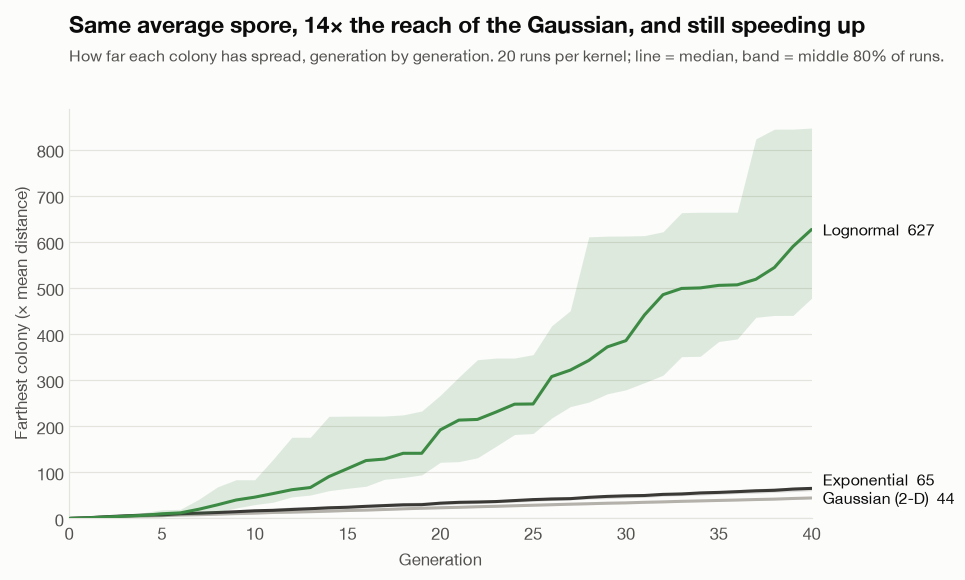

In [9]:
gens = np.arange(G_SAFE + 1)
fig, ax = plt.subplots(figsize=(10, 5.4))
fig.subplots_adjust(top=0.80, right=0.80)

ends = {}
for name in ("gaussian", "exponential", "lognormal"):
    f = fronts[name][:, :G_SAFE + 1]
    med = np.median(f, axis=0)
    lo, hi = np.percentile(f, [10, 90], axis=0)
    z = 3 if name == "lognormal" else 2
    ax.fill_between(gens, lo, hi, color=COLORS[name], alpha=0.16, linewidth=0, zorder=z - 1)
    ax.plot(gens, med, color=COLORS[name], lw=2, label=LABELS[name], zorder=z)
    ends[name] = med[-1]

ax.set_xlim(0, G_SAFE)
ax.set_ylim(0, None)

# End labels, nudged apart so lines that finish close together don't collide
min_gap = 0.045 * ax.get_ylim()[1]
label_y = {}
for name in sorted(ends, key=ends.get):
    y = ends[name]
    if label_y:
        y = max(y, max(label_y.values()) + min_gap)
    label_y[name] = y
for name, y in label_y.items():
    ax.annotate(f"{LABELS[name]}  {ends[name]:.0f}", (gens[-1], ends[name]), xytext=(gens[-1] + 0.6, y),
                textcoords="data", va="center", fontsize=10.5, color=INK, annotation_clip=False)
ax.grid(axis="y", color=HAIRLINE, lw=0.8)
ax.set_xlabel("Generation")
ax.set_ylabel("Farthest colony (× mean distance)")
# every line is labelled at its end, so no legend

ratio = np.median(fronts["lognormal"][:, G_SAFE]) / np.median(fronts["gaussian"][:, G_SAFE])
# Only claim acceleration if the data shows it: 2nd-half speed clearly above 1st-half speed
med_ln = np.median(fronts["lognormal"][:, :G_SAFE + 1], axis=0)
v1 = (med_ln[half] - med_ln[0]) / half
v2 = (med_ln[G_SAFE] - med_ln[half]) / (G_SAFE - half)
title = f"Same average spore, {ratio:.0f}× the reach of the Gaussian"
if v2 > 1.5 * v1:
    title += ", and still speeding up"
fig.text(0.125, 0.965, title, fontsize=15, weight="bold", va="top")
fig.text(0.125, 0.905, f"How far each colony has spread, generation by generation. {RUNS} runs per kernel; "
         f"line = median, band = middle 80% of runs.", fontsize=10.5, color=INK_2, va="top")
fig.savefig(FIGURES / "fig3_spread_race.png")
plt.show()

**What this shows.** All three kernels move spores the same average distance, but after 40 generations the lognormal colony's farthest outpost is about 14× farther out than the Gaussian's (627 vs. 44 mean distances).

The thin-tailed colonies **creep**: their fronts advance at a steady ~1–2 mean distances per generation. The lognormal colony **jumps**, and it accelerates: its front moves about 10 mean distances per generation in the first half and about 22 in the second. As the colony grows it releases more spores, so it samples the rare long jumps more often, and each long jump starts a new front.

## 4. Weibull waiting times

On the page, once a moss patch is mature and undisturbed, it waits a random time $T$ before a fern unfurls from it. $T$ follows a **Weibull distribution**:

$$f(t; k, \lambda) = \frac{k}{\lambda}\left(\frac{t}{\lambda}\right)^{k-1} e^{-(t/\lambda)^k}$$

Weibull is a standard model for time-to-event data, including germination times, because one parameter, the shape $k$, controls how the chance of the event changes as time passes:

- $k < 1$: the event is most likely early, and gets less likely the longer you wait.
- $k = 1$: the chance per second is constant; this is the exponential distribution, which has no memory.
- $k > 1$: the chance per second grows the longer you wait, like a seed that's getting ready.

The scale $\lambda$ stretches the timescale.

In [10]:
# Once a moss patch is mature and undisturbed, it waits T seconds before a fern unfurls,
# with T ~ Weibull(k, λ). The choice of values is explained after the figures.
WEIBULL_K = 3.0        # k > 1: the longer a patch has waited, the more ready it is
WEIBULL_LAMBDA = 12.0  # scale, in seconds

weibull = stats.weibull_min(c=WEIBULL_K, scale=WEIBULL_LAMBDA)
q05, q50, q95 = weibull.ppf([0.05, 0.5, 0.95])
print(f"median wait {q50:.1f} s   (formula: λ·(ln 2)^(1/k) = {WEIBULL_LAMBDA * np.log(2) ** (1 / WEIBULL_K):.1f} s)")
print(f"90% of ferns unfurl between {q05:.1f} s and {q95:.1f} s")

median wait 10.6 s   (formula: λ·(ln 2)^(1/k) = 10.6 s)
90% of ferns unfurl between 4.5 s and 17.3 s


### Figure 4: what the shape k does

Same scale λ, three shapes. Left: when ferns unfurl. Right: the **hazard**, the chance per second that a fern unfurls *given that it hasn't yet*. The hazard is what k really controls:

$$h(t) = \frac{k}{\lambda}\left(\frac{t}{\lambda}\right)^{k-1}$$

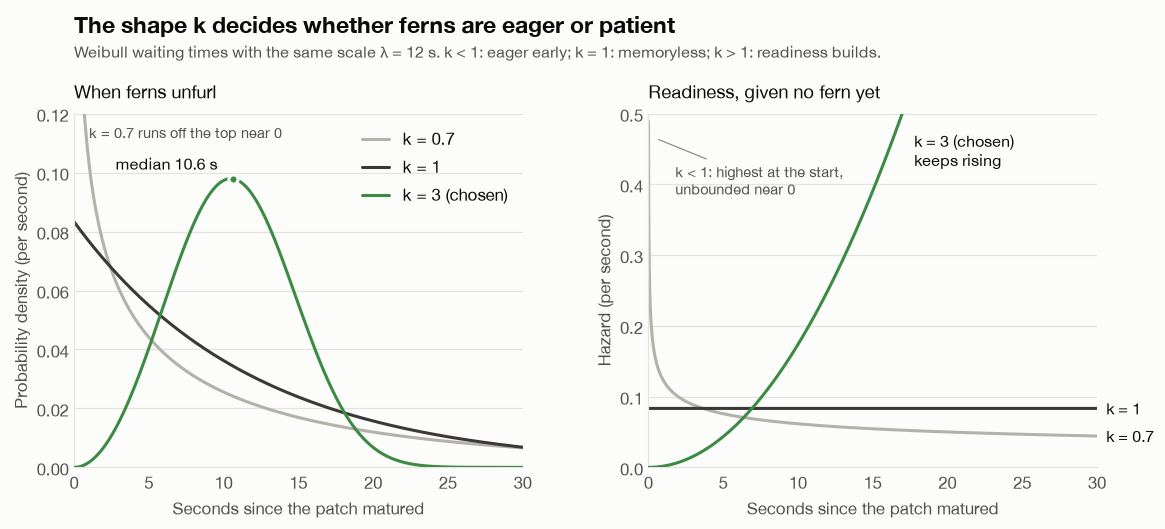

In [11]:
SHAPES = {0.7: "k = 0.7", 1.0: "k = 1", WEIBULL_K: f"k = {WEIBULL_K:g} (chosen)"}
SHAPE_COLORS = {0.7: COLORS["gaussian"], 1.0: COLORS["exponential"], WEIBULL_K: COLORS["lognormal"]}  # green = the model we use
T_MAX = 30
t = np.linspace(0.01, T_MAX, 3000)

def hazard(t, k, lam=WEIBULL_LAMBDA):
    return (k / lam) * (t / lam) ** (k - 1)

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"wspace": 0.28})
fig.subplots_adjust(top=0.78)

Y_PDF, Y_HAZ = 0.12, 0.5   # shared top limits; k < 1 shoots past them near t = 0
for k, label in SHAPES.items():
    w = stats.weibull_min(c=k, scale=WEIBULL_LAMBDA)
    z = 3 if k == WEIBULL_K else 2
    left.plot(t, w.pdf(t), color=SHAPE_COLORS[k], lw=2, zorder=z, label=label)
    right.plot(t, hazard(t, k), color=SHAPE_COLORS[k], lw=2, zorder=z)

for ax, ylim in ((left, Y_PDF), (right, Y_HAZ)):
    ax.set_xlim(0, T_MAX)
    ax.set_ylim(0, ylim)
    ax.grid(axis="y", color=HAIRLINE, lw=0.8)
    ax.set_xlabel("Seconds since the patch matured")

left.set_ylabel("Probability density (per second)")
left.set_title("When ferns unfurl", color=INK)
left.legend(loc="upper right", handlelength=1.6)
left.text(1.0, Y_PDF * 0.97, "k = 0.7 runs off the top near 0", fontsize=9.5, color=INK_2, va="top")
right.set_ylabel("Hazard (per second)")
right.set_title("Readiness, given no fern yet", color=INK)

# Direct labels on the hazard panel. The flat-ish ones end at the right edge; the chosen k
# leaves through the top, so it is labelled where it exits.
for k in (0.7, 1.0):
    right.annotate(SHAPES[k], (T_MAX, hazard(T_MAX, k)), xytext=(6, 0), textcoords="offset points",
                   va="center", fontsize=10.5, color=INK, annotation_clip=False)
t_exit = WEIBULL_LAMBDA * (Y_HAZ * WEIBULL_LAMBDA / WEIBULL_K) ** (1 / (WEIBULL_K - 1))
right.text(t_exit + 0.8, Y_HAZ * 0.95, f"{SHAPES[WEIBULL_K]}\nkeeps rising", fontsize=10.5, color=INK, va="top")
right.annotate("k < 1: highest at the start,\nunbounded near 0", (0.5, Y_HAZ * 0.93),
               xytext=(1.8, Y_HAZ * 0.86), fontsize=9.5, color=INK_2, va="top",
               arrowprops=dict(arrowstyle="-", color=INK_3, lw=0.8))
left.annotate(f"median {q50:.1f} s", (q50, weibull.pdf(q50)), xytext=(-10, 6), textcoords="offset points",
              ha="right", fontsize=10.5, color=INK)
left.plot(q50, weibull.pdf(q50), "o", ms=6, color=COLORS["lognormal"], mec=SURFACE, mew=2, zorder=4)

fig.text(0.125, 0.975, "The shape k decides whether ferns are eager or patient", fontsize=15, weight="bold", va="top")
fig.text(0.125, 0.915, f"Weibull waiting times with the same scale λ = {WEIBULL_LAMBDA:g} s. "
         "k < 1: eager early; k = 1: memoryless; k > 1: readiness builds.", fontsize=10.5, color=INK_2, va="top")

fig.savefig(FIGURES / "fig4_weibull_shapes.png")
plt.show()

### Sampling by inverse transform

If $U \sim \text{Uniform}(0,1)$, then $-\ln U \sim \text{Exponential}(1)$, and

$$T = \lambda\,(-\ln U)^{1/k}$$

is Weibull$(k, \lambda)$. One uniform random number in, one waiting time out. This is the sampler the homepage uses.

In [12]:
# Inverse-transform sampling: if U ~ Uniform(0, 1), then -ln U ~ Exponential(1),
# and T = λ·(-ln U)^(1/k) is Weibull(k, λ). The homepage samples the same way.
def sample_weibull(k, lam, size, rng):
    u = rng.uniform(size=size)
    return lam * (-np.log(u)) ** (1 / k)

T = sample_weibull(WEIBULL_K, WEIBULL_LAMBDA, 100_000, rng)
ks = stats.kstest(T, weibull.cdf)
print(f"sample median {np.median(T):.2f} s vs {q50:.2f} s (formula)   KS p = {ks.pvalue:.2f}")
assert ks.pvalue > 0.01, "the sampler doesn't match the distribution"

sample median 10.62 s vs 10.62 s (formula)   KS p = 0.60


### Figure 5: checking the sampler

100,000 draws from the one-line formula, against scipy's Weibull density.

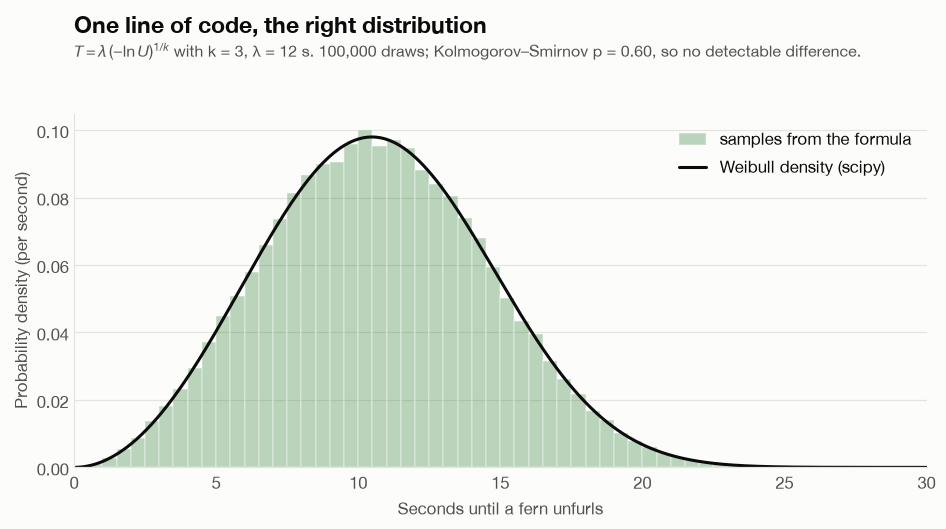

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.8))
fig.subplots_adjust(top=0.78)

bins = np.arange(0, T_MAX + 0.5, 0.5)
ax.hist(T, bins=bins, density=True, color=COLORS["lognormal"], alpha=0.35, edgecolor=SURFACE, linewidth=1,
        label="samples from the formula")
ax.plot(t, weibull.pdf(t), color=INK, lw=2, label="Weibull density (scipy)")
ax.set_xlim(0, T_MAX)
ax.set_ylim(0, None)
ax.grid(axis="y", color=HAIRLINE, lw=0.8)
ax.set_axisbelow(True)
ax.set_xlabel("Seconds until a fern unfurls")
ax.set_ylabel("Probability density (per second)")
ax.legend(loc="upper right", handlelength=1.6)

fig.text(0.125, 0.975, "One line of code, the right distribution", fontsize=15, weight="bold", va="top")
fig.text(0.125, 0.915, rf"$T = \lambda\,(-\ln U)^{{1/k}}$ with k = {WEIBULL_K:g}, λ = {WEIBULL_LAMBDA:g} s. "
         f"{len(T):,} draws; Kolmogorov–Smirnov p = {ks.pvalue:.2f}, so no detectable difference.",
         fontsize=10.5, color=INK_2, va="top")

fig.savefig(FIGURES / "fig5_weibull_sampler.png")
plt.show()

**Chosen values: $k = 3$, $\lambda = 12$ s.** With $k = 3$, readiness builds with stillness, so ferns come to visitors who stay rather than appearing at random. With $\lambda = 12$ s, the median wait is 10.6 s and 90% of ferns unfurl between 4.5 and 17.3 s: long enough to feel like a reward for staying, short enough that a patient visitor will see one.

## 5. Summary

| Parameter | Value | Why |
| --- | --- | --- |
| Dispersal kernel | lognormal, $s = 1.5$, mean distance 1 | Fat tail: rare long jumps make the spread accelerate (sections 2–3) |
| Weibull shape $k$ | 3 | Readiness builds with stillness (section 4) |
| Weibull scale $\lambda$ | 12 s | Median first fern after ~10.6 s of stillness (section 4) |

## References

- Clark, J. S. (1998). Why trees migrate so fast: confronting theory with dispersal biology and the paleorecord. *The American Naturalist*, 152(2), 204–224.